COPY !

In [1]:
# (cell 1) - Install kaggle
!pip install -q kaggle

In [2]:
# (cell 2) - Upload kaggle.json
from google.colab import files
files.upload()  # Upload kaggle.json


Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"shrutikumarijsr","key":"215d1f89574daa8294723b7f2b076427"}'}

In [3]:
# (cell 3) - Set up kaggle API key
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json


In [4]:
# (cell 4) - Download & extract dataset
!kaggle datasets download -d nikhilgurav21/nail-disease-detection-dataset
!unzip -q nail-disease-detection-dataset.zip -d nail_dataset

Dataset URL: https://www.kaggle.com/datasets/nikhilgurav21/nail-disease-detection-dataset
License(s): CC-BY-NC-SA-4.0
  0% 0.00/63.8M [00:00<?, ?B/s]
100% 63.8M/63.8M [00:00<00:00, 974MB/s]


In [5]:
# (cell 5) - Set random seed
import tensorflow as tf, numpy as np, random, os
seed = 42
os.environ['PYTHONHASHSEED'] = str(seed)
random.seed(seed); np.random.seed(seed); tf.random.set_seed(seed)


In [6]:
# (cell 6) - Combine train and val from original dataset
import shutil
combined_data_path = "combined_data"
train_path = "nail_dataset/data/train"
val_path = "nail_dataset/data/validation"

os.makedirs(combined_data_path, exist_ok=True)
for cls in os.listdir(train_path):
    os.makedirs(f"{combined_data_path}/{cls}", exist_ok=True)
    for folder in (train_path, val_path):
        for fn in os.listdir(f"{folder}/{cls}"):
            shutil.copy(f"{folder}/{cls}/{fn}", f"{combined_data_path}/{cls}/{fn}")

In [7]:
# (cell 6.0) - Split combined data into train, val, test
from sklearn.model_selection import train_test_split
import shutil
import os

combined_data_path = "combined_data"
split_base = "final_split"

# Clear if it already exists
shutil.rmtree(split_base, ignore_errors=True)

for cls in os.listdir(combined_data_path):
    cls_path = os.path.join(combined_data_path, cls)
    images = os.listdir(cls_path)

    # 70% train, 15% val, 15% test
    train_imgs, temp_imgs = train_test_split(images, test_size=0.3, random_state=42)
    val_imgs, test_imgs = train_test_split(temp_imgs, test_size=0.5, random_state=42)

    for split, split_imgs in zip(["train", "val", "test"], [train_imgs, val_imgs, test_imgs]):
        split_dir = os.path.join(split_base, split, cls)
        os.makedirs(split_dir, exist_ok=True)
        for img in split_imgs:
            src = os.path.join(cls_path, img)
            dst = os.path.join(split_dir, img)
            shutil.copy(src, dst)


In [8]:
# (cell 6.1) — Static Augmentation of Training Set
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array, array_to_img
import os

train_dir = "final_split/train"
augmentor = ImageDataGenerator(
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

augmentations_per_image = 1  # Number of augmented copies per original image
augmented_count = 0

for cls in os.listdir(train_dir):
    cls_path = os.path.join(train_dir, cls)
    for img_name in os.listdir(cls_path):
        img_path = os.path.join(cls_path, img_name)
        try:
            img = load_img(img_path)
            x = img_to_array(img)
            x = x.reshape((1,) + x.shape)

            for i, batch in enumerate(augmentor.flow(x, batch_size=1)):
                aug_img = array_to_img(batch[0])
                aug_img.save(os.path.join(cls_path, f"aug_{i}_{img_name}"))
                augmented_count += 1
                if i + 1 >= augmentations_per_image:
                    break
        except Exception as e:
            print(f"Error augmenting {img_path}: {e}")

print(f"✅ Total augmented images added: {augmented_count}")


✅ Total augmented images added: 2683


In [9]:
# (cell 6.2)
import os

split_base = "final_split"
splits = ['train', 'val', 'test']
counts = {split: 0 for split in splits}

for split in splits:
    split_dir = os.path.join(split_base, split)
    for cls in os.listdir(split_dir):
        class_path = os.path.join(split_dir, cls)
        counts[split] += len(os.listdir(class_path))

print("Image count per split:")
for split in splits:
    print(f"{split.capitalize()}: {counts[split]} images")
print(f"Total: {sum(counts.values())} images")


Image count per split:
Train: 5366 images
Val: 574 images
Test: 578 images
Total: 6518 images


In [10]:
# (cell 7.0)
#!pip install tensorflow scikit-learn pandas


In [10]:
# (cell 7) - Imports and model builder
def build_model(base_model, num_classes):
    inputs = tf.keras.Input(shape=(224, 224, 3))
    x = base_model(inputs, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(128, activation='relu')(x)
    x = tf.keras.layers.Dropout(0.5)(x)
    outputs = tf.keras.layers.Dense(num_classes, activation='softmax')(x)
    model = tf.keras.Model(inputs, outputs)
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

from sklearn.model_selection import StratifiedKFold
from tensorflow.keras.applications import ResNet50, VGG16, MobileNetV2, EfficientNetB0
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg_preprocess
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess
from tensorflow.keras.applications.efficientnet import preprocess_input as efficientnet_preprocess
from tensorflow.keras.applications.efficientnet_v2 import EfficientNetV2S
from tensorflow.keras.applications.efficientnet_v2 import preprocess_input as efficientnetv2_preprocess

from tensorflow.keras.callbacks import EarlyStopping
import pandas as pd

img_size = (224, 224)
batch_size = 32

In [11]:
# (cell 8) — k-Fold machinery for static augmentation

def create_dataframe(data_dir):
    rows = []
    for cls in sorted(os.listdir(data_dir)):
        for fn in os.listdir(f"{data_dir}/{cls}"):
            rows.append({"filepath": f"{data_dir}/{cls}/{fn}", "label": cls})
    return pd.DataFrame(rows)

def make_dataset(filepaths, labels, preprocess_fn, num_classes):
    filepaths = tf.constant(filepaths)
    labels = tf.constant(labels, dtype=tf.int32)

    def _load_and_prep(path, label):
        img = tf.io.read_file(path)
        img = tf.image.decode_jpeg(img, channels=3)
        img = tf.image.resize(img, img_size)
        img = preprocess_fn(tf.cast(img, tf.float32))  # preprocess as expected by model
        label = tf.one_hot(label, num_classes)
        return img, label

    ds = tf.data.Dataset.from_tensor_slices((filepaths, labels))
    ds = ds.map(_load_and_prep, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.shuffle(1000).batch(batch_size).prefetch(tf.data.AUTOTUNE)




"""def run_kfold_training(name, base_fn, preprocess_fn, k=2):
    print(f"\n=== {k}-Fold for {name} ===")
    df = create_dataframe(combined_data_path)
    class_names = sorted(df.label.unique())
    class_to_idx = {c: i for i, c in enumerate(class_names)}
    df["label_idx"] = df.label.map(class_to_idx)

    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)
    histories = []

    for fold, (train_i, val_i) in enumerate(skf.split(df.filepath, df.label_idx), start=1):
        print(f"--- fold {fold} ---")
        train_df = df.iloc[train_i]
        val_df = df.iloc[val_i]

        train_ds = make_dataset(train_df.filepath.tolist(), train_df.label_idx.tolist(), preprocess_fn, len(class_names))
        val_ds = make_dataset(val_df.filepath.tolist(), val_df.label_idx.tolist(), preprocess_fn, len(class_names))

        model = build_model(base_fn(include_top=False, input_shape=img_size + (3,)), len(class_names))

        es = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1)
        hist = model.fit(train_ds, validation_data=val_ds, epochs=20, callbacks=[es], verbose=1)

        if es.stopped_epoch > 0:
            print(f"⏹️ Early stopping at epoch {es.stopped_epoch + 1} in fold {fold}")

        if fold == 2:
          model.save("efficientnetv2s_best_fold.h5")
        histories.append(hist.history)

    return histories"""

'def run_kfold_training(name, base_fn, preprocess_fn, k=2):\n    print(f"\n=== {k}-Fold for {name} ===")\n    df = create_dataframe(combined_data_path)\n    class_names = sorted(df.label.unique())\n    class_to_idx = {c: i for i, c in enumerate(class_names)}\n    df["label_idx"] = df.label.map(class_to_idx)\n\n    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)\n    histories = []\n\n    for fold, (train_i, val_i) in enumerate(skf.split(df.filepath, df.label_idx), start=1):\n        print(f"--- fold {fold} ---")\n        train_df = df.iloc[train_i]\n        val_df = df.iloc[val_i]\n\n        train_ds = make_dataset(train_df.filepath.tolist(), train_df.label_idx.tolist(), preprocess_fn, len(class_names))\n        val_ds = make_dataset(val_df.filepath.tolist(), val_df.label_idx.tolist(), preprocess_fn, len(class_names))\n\n        model = build_model(base_fn(include_top=False, input_shape=img_size + (3,)), len(class_names))\n\n        es = EarlyStopping(monitor="val_loss

In [12]:
# (cell 8.1)

import os

split_base = "final_split"
splits = ['train', 'val', 'test']
counts = {split: 0 for split in splits}

for split in splits:
    split_dir = os.path.join(split_base, split)
    for cls in os.listdir(split_dir):
        class_path = os.path.join(split_dir, cls)
        counts[split] += len(os.listdir(class_path))

print("📊 Image count per split:")
for split in splits:
    print(f"{split.capitalize()}: {counts[split]} images")
print(f"Total: {sum(counts.values())} images")


📊 Image count per split:
Train: 5366 images
Val: 574 images
Test: 578 images
Total: 6518 images


In [13]:
# (cell 9) - Manual 70-15-15 split (for final presentation testing)
from sklearn.model_selection import train_test_split
split_base = "final_split"
shutil.rmtree(split_base, ignore_errors=True)

for cls in os.listdir(combined_data_path):
    cls_path = os.path.join(combined_data_path, cls)
    images = os.listdir(cls_path)

    train_imgs, temp_imgs = train_test_split(images, test_size=0.3, random_state=42)
    val_imgs, test_imgs = train_test_split(temp_imgs, test_size=0.5, random_state=42)

    for split, split_imgs in zip(["train", "val", "test"], [train_imgs, val_imgs, test_imgs]):
        split_dir = os.path.join(split_base, split, cls)
        os.makedirs(split_dir, exist_ok=True)
        for img in split_imgs:
            shutil.copy(os.path.join(cls_path, img), os.path.join(split_dir, img))

In [14]:
# (cell 9.0)
from tensorflow.keras.applications import EfficientNetV2S
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

# Load base EfficientNetV2S model without top layers
base_model = EfficientNetV2S(include_top=False, weights='imagenet', input_shape=(224, 224, 3))

# Freeze base model initially
base_model.trainable = False

# Add custom head
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.2)(x)
predictions = Dense(6, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=predictions)

# Compile model
model.compile(optimizer=Adam(learning_rate=0.0001), loss='categorical_crossentropy', metrics=['accuracy'])


82420632/82420632 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


In [16]:
# (cell 9.1) - Normal training using train/val/test folders (no k-fold)

train_df = create_dataframe("final_split/train")
val_df = create_dataframe("final_split/val")
# ✅ Count number of images per class in validation set
val_class_counts = val_df['label'].value_counts()
print("📊 Number of images per class in validation set:")
print(val_class_counts)
test_df = create_dataframe("final_split/test")

class_names = sorted(train_df.label.unique())
class_to_idx = {c: i for i, c in enumerate(class_names)}
train_df["label_idx"] = train_df.label.map(class_to_idx)
val_df["label_idx"] = val_df.label.map(class_to_idx)
test_df["label_idx"] = test_df.label.map(class_to_idx)

train_ds = make_dataset(train_df.filepath.tolist(), train_df.label_idx.tolist(), efficientnetv2_preprocess, len(class_names))
val_ds = make_dataset(val_df.filepath.tolist(), val_df.label_idx.tolist(), efficientnetv2_preprocess, len(class_names))
test_ds = make_dataset(test_df.filepath.tolist(), test_df.label_idx.tolist(), efficientnetv2_preprocess, len(class_names))

# ✅ Already defined transfer learning model in previous cell, so don’t re-define it here
# model = build_model(...)  ← commented

# ✅ Early stopping and model checkpoint
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

es = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1)
checkpoint = ModelCheckpoint("efficientnetv2s_model.h5", save_best_only=True)

# ✅ Train
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    callbacks=[es, checkpoint],
    verbose=1
)

# Optional: Evaluate test set
# test_loss, test_acc = model.evaluate(test_ds)
# print(f"✅ Test Accuracy: {test_acc:.4f}")


📊 Number of images per class in validation set:
label
clubbing                      117
Acral_Lentiginous_Melanoma    113
Onychogryphosis               103
pitting                        98
blue_finger                    92
Healthy_Nail                   51
Name: count, dtype: int64
Epoch 1/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 379ms/step - accuracy: 0.2745 - loss: 1.7271

84/84 ━━━━━━━━━━━━━━━━━━━━ 105s 633ms/step - accuracy: 0.2750 - loss: 1.7267 - val_accuracy: 0.4512 - val_loss: 1.4483
Epoch 2/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - accuracy: 0.4012 - loss: 1.5122

84/84 ━━━━━━━━━━━━━━━━━━━━ 12s 128ms/step - accuracy: 0.4021 - loss: 1.5108 - val_accuracy: 0.5871 - val_loss: 1.1736
Epoch 3/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.5382 - loss: 1.2480

84/84 ━━━━━━━━━━━━━━━━━━━━ 12s 131ms/step - accuracy: 0.5386 - loss: 1.2472 - val_accuracy: 0.6307 - val_loss: 1.0059
Epoch 4/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - accuracy: 0.6170 - loss: 1.0902

84/84 ━━━━━━━━━━━━━━━━━━━━ 12s 128ms/step - accuracy: 0.6173 - loss: 1.0893 - val_accuracy: 0.6760 - val_loss: 0.8946
Epoch 5/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step - accuracy: 0.6570 - loss: 0.9555

84/84 ━━━━━━━━━━━━━━━━━━━━ 12s 131ms/step - accuracy: 0.6572 - loss: 0.9548 - val_accuracy: 0.6899 - val_loss: 0.8145
Epoch 6/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step - accuracy: 0.6838 - loss: 0.8878

... (29 outputs left out)

84/84 ━━━━━━━━━━━━━━━━━━━━ 12s 134ms/step - accuracy: 0.8688 - loss: 0.3789 - val_accuracy: 0.8362 - val_loss: 0.4127
Epoch 47/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 0.8632 - loss: 0.3803

84/84 ━━━━━━━━━━━━━━━━━━━━ 12s 133ms/step - accuracy: 0.8632 - loss: 0.3804 - val_accuracy: 0.8397 - val_loss: 0.4088
Epoch 48/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 19s 119ms/step - accuracy: 0.8691 - loss: 0.3598 - val_accuracy: 0.8362 - val_loss: 0.4105
Epoch 49/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step - accuracy: 0.8677 - loss: 0.3828

84/84 ━━━━━━━━━━━━━━━━━━━━ 21s 129ms/step - accuracy: 0.8677 - loss: 0.3828 - val_accuracy: 0.8467 - val_loss: 0.4087
Epoch 50/50
84/84 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 0.8634 - loss: 0.3802

84/84 ━━━━━━━━━━━━━━━━━━━━ 12s 130ms/step - accuracy: 0.8635 - loss: 0.3802 - val_accuracy: 0.8432 - val_loss: 0.4015
Restoring model weights from the end of the best epoch: 50.


**Load model from saved file**

In [18]:
# (cell 10)
# ✅ Load model from saved file (if already trained previously)
from tensorflow.keras.models import load_model
model = load_model("efficientnetv2s_model.h5")
print("✅ Model loaded from efficientnetv2s_model.h5")


✅ Model loaded from efficientnetv2s_model.h5


In [20]:
# TO DOWNLOAD THE SAVED MODEL SO THAT NO NEED TO RE_TRAIN IT AGAIN AND AGAIN ------------

# from google.colab import files
# files.download("efficientnetv2s_model.h5")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
# ------------- TO UPLOAD THE DOWNLOADED MODEL LOCALLY USE THIS -------------------
# from google.colab import files
# uploaded = files.upload()


In [21]:
# (cell 11) ✅ Load and Evaluate Model
from tensorflow.keras.models import load_model

model = load_model("efficientnetv2s_model.h5")
print("✅ Loaded best model")

# ✅ Evaluate Accuracy
loss, acc = model.evaluate(train_ds)
print(f"📊 Train Accuracy: {acc*100:.2f}%")

loss, acc = model.evaluate(val_ds)
print(f"📊 Validation Accuracy: {acc*100:.2f}%")


✅ Loaded best model
84/84 ━━━━━━━━━━━━━━━━━━━━ 25s 138ms/step - accuracy: 0.9214 - loss: 0.2492
📊 Train Accuracy: 92.43%
18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 318ms/step - accuracy: 0.8484 - loss: 0.3989
📊 Validation Accuracy: 84.32%


1/1 ━━━━━━━━━━━━━━━━━━━━ 17s 17s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 179ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 152ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 214ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 195ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 230ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 212ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 219ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 213ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 164ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 153ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 17s 17s/step

📊 Classification Report (Validation Data):
                            precision    recall  f1-score   support

Acral_Lentiginous_Melanoma       0.94      0.79      0.86       113
              Healthy_Nail       1.00      1.00      1.00        51
           Onychogryphosis       0.90      0.84    

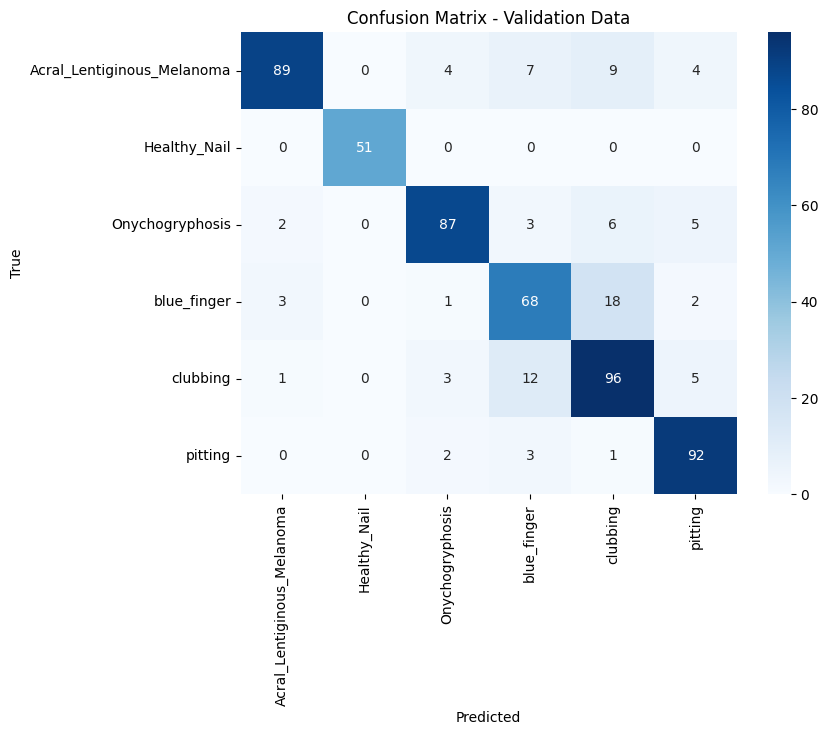

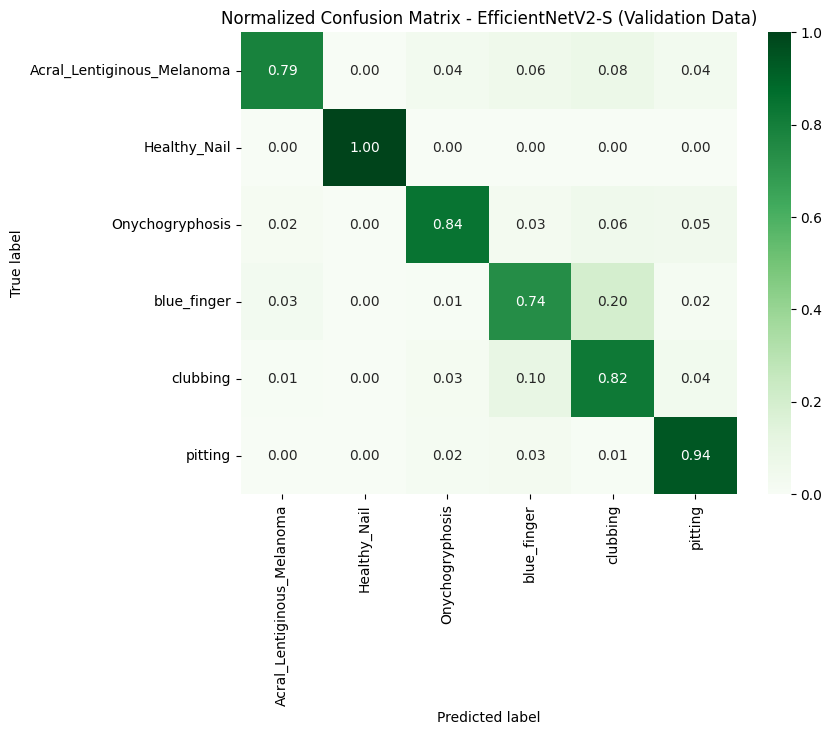

In [20]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Unbatch the validation dataset and extract true labels and predictions
y_true = []
y_pred = []

for batch_x, batch_y in val_ds:
    preds = model.predict(batch_x)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(np.argmax(batch_y.numpy(), axis=1))  # convert one-hot to integer labels

# Convert to numpy arrays
y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Classification Report
print("\n📊 Classification Report (Validation Data):")
print(classification_report(y_true, y_pred, target_names=class_names))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=class_names, yticklabels=class_names, cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix - Validation Data")
plt.show() now will it predict correctly ?

# Normalized Confusion Matrix
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
df_cm = pd.DataFrame(cm_normalized, index=class_names, columns=class_names)
plt.figure(figsize=(8,6))
sns.heatmap(df_cm, annot=True, cmap="Greens", fmt=".2f")
plt.title("Normalized Confusion Matrix - EfficientNetV2-S (Validation Data)")
plt.ylabel("True label")
plt.xlabel("Predicted label")
plt.show()


In [21]:
!pip install google-generativeai langchain faiss-cpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.3/31.3 MB 26.7 MB/s eta 0:00:00


In [22]:
!pip install -U langchain-community


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 77.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.2/45.2 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.9/50.9 kB 5.0 MB/s eta 0:00:00


In [23]:
!pip install gradio transformers langchain langchain-community

In [24]:
# 📄 Create a sample diseases_knowledge.txt file
sample_data = """
Onychogryphosis is a condition where the nail becomes abnormally thickened and curved. Temporary care includes regular trimming and softening the nail with warm water soaks. In severe cases, a podiatrist may need to remove it.

Acral Lentiginous Melanoma is a type of skin cancer that appears on the nails, palms, or soles. Early detection is critical. Patients should see a dermatologist immediately for further testing.

Blue finger (cyanosis) may indicate poor circulation or oxygen deficiency. Temporary care involves warming the area and checking for underlying causes.

Nail pitting is associated with psoriasis and autoimmune diseases. Moisturizers and gentle care are recommended. Avoid nail trauma.

Clubbing is when the fingers swell and nails become rounder. It may signal heart or lung issues. Consult a healthcare provider.

Healthy nails are smooth, evenly colored, and free of damage. To maintain healthy nails, keep them clean, moisturized, and trim them regularly.
"""

with open("diseases_knowledge.txt", "w") as f:
    f.write(sample_data)

print("✅ Created diseases_knowledge.txt")


✅ Created diseases_knowledge.txt


In [25]:
# 📌 Install Hugging Face Hub
!pip install -q huggingface_hub

# 🔐 Login with your Hugging Face token (replace YOUR_TOKEN with your actual token)
from huggingface_hub import login
login()  # prompts for your token; never paste it into the notebook


In [26]:

# ✅ Imports
from langchain.vectorstores import FAISS
from langchain.embeddings import HuggingFaceEmbeddings
from langchain.document_loaders import TextLoader
from langchain.text_splitter import CharacterTextSplitter
from transformers import AutoModelForCausalLM, AutoTokenizer
import tensorflow as tf
import numpy as np
#import gradio as gr
import torch
from tensorflow.keras.models import load_model

# ✅ Load Chat Model
chat_tokenizer = AutoTokenizer.from_pretrained("mistralai/Mistral-7B-Instruct-v0.1")
chat_model = AutoModelForCausalLM.from_pretrained("mistralai/Mistral-7B-Instruct-v0.1", device_map="auto")
chat_history = []  # To maintain conversation context

# ✅ Prediction Agent
class PredictionAgent:
    def __init__(self, model, class_names):
        self.model = model
        self.class_names = class_names

    def predict(self, image_path):
        img = tf.keras.preprocessing.image.load_img(image_path, target_size=(224, 224))
        img = tf.keras.preprocessing.image.img_to_array(img) / 255.0
        img = np.expand_dims(img, axis=0)
        preds = self.model.predict(img)
        return self.class_names[np.argmax(preds)]

# ✅ RAG Agent
class RAGAgent:
    def __init__(self, doc_path):
        loader = TextLoader(doc_path)
        docs = loader.load()
        splitter = CharacterTextSplitter(chunk_size=500, chunk_overlap=50)
        split_docs = splitter.split_documents(docs)
        embeddings = HuggingFaceEmbeddings()
        self.vectorstore = FAISS.from_documents(split_docs, embeddings)

    def retrieve(self, query, k=2):
        results = self.vectorstore.similarity_search(query, k=k)
        return "\n".join([r.page_content for r in results])

# ✅ Chat Generator
def generate_response(disease, context, user_input):
    system_prompt = f"You are a helpful medical assistant. The predicted nail disease is: {disease}.\nHere is the relevant context:\n{context}"
    messages = [system_prompt] + chat_history + [f"User: {user_input}", "Assistant:"]
    input_text = "\n".join(messages)

    inputs = chat_tokenizer.encode(input_text, return_tensors="pt").to(chat_model.device)
    attention_mask = torch.ones(inputs.shape, dtype=torch.long).to(chat_model.device)

    outputs = chat_model.generate(
        inputs,
        attention_mask=attention_mask,
        max_new_tokens=300,
        pad_token_id=chat_tokenizer.eos_token_id
    )
    response = chat_tokenizer.decode(outputs[0], skip_special_tokens=True).split("Assistant:")[-1].strip()

    chat_history.append(f"User: {user_input}")
    chat_history.append(f"Assistant: {response}")
    return response

# ✅ Full Assistant Wrapper
class NailDiseaseAssistant:
    def __init__(self, model, class_names, doc_path):
        self.predictor = PredictionAgent(model, class_names)
        self.rag = RAGAgent(doc_path)

    def run(self, image_path, user_input):
        disease = self.predictor.predict(image_path)
        context = self.rag.retrieve(disease)
        response = generate_response(disease, context, user_input)
        return disease, response

# ✅ Load Model and Define Class Names
model = load_model("efficientnetv2s_model.h5")
class_names = ['Acral_Lentiginous_Melanoma','Healthy_Nail','Onychogryphosis','blue_finger','clubbing','pitting']
assistant = NailDiseaseAssistant(model, class_names, "diseases_knowledge.txt")




/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/2.10k [00:00<?, ?B/s]

tokenizer.model:   0%|          | 0.00/493k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.80M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

... (14 outputs left out)

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [27]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Define image size and batch size
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Create generators for train and val
train_datagen = ImageDataGenerator(rescale=1./255)
val_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    '/content/final_split/train',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

val_generator = val_datagen.flow_from_directory(
    '/content/final_split/val',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)


Found 2683 images belonging to 6 classes.
Found 574 images belonging to 6 classes.


In [28]:
loss, acc = model.evaluate(train_generator)
print(f"📊 Train Accuracy: {acc*100:.2f}%")

loss, acc = model.evaluate(val_generator)
print(f"📊 Validation Accuracy: {acc*100:.2f}%")


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


84/84 ━━━━━━━━━━━━━━━━━━━━ 27s 135ms/step - accuracy: 0.2798 - loss: 1.8447
📊 Train Accuracy: 27.39%
18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 311ms/step - accuracy: 0.2698 - loss: 1.8432
📊 Validation Accuracy: 25.61%


In [29]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Define image size and batch size
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Create generators for train and val
train_datagen = ImageDataGenerator(rescale=1./255)
val_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    '/content/final_split/train',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

val_generator = val_datagen.flow_from_directory(
    '/content/final_split/val',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)


Found 2683 images belonging to 6 classes.
Found 574 images belonging to 6 classes.


In [30]:
loss, acc = model.evaluate(train_generator)


84/84 ━━━━━━━━━━━━━━━━━━━━ 7s 87ms/step - accuracy: 0.2725 - loss: 1.8781


In [ ]:
# ✅ Manual test without Gradio



from PIL import Image
import shutil

# Upload your test image (you can skip this if you already have an image in /content/)
from google.colab import files
uploaded = files.upload()

# Get the uploaded image path
image_path = list(uploaded.keys())[0]

# Ask any question about the disease
user_question = "What is this disease?"

# Run the assistant directly
disease, response = assistant.run(image_path, user_question)

print("🧪 Predicted Disease:", disease)
print("\n🤖 Assistant:\n", response)


Saving 100_JPG.rf.a80bfbf37fe7c3ba475cd65f7bab9b34.jpg to 100_JPG.rf.a80bfbf37fe7c3ba475cd65f7bab9b34.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step


In [ ]:
from IPython.display import Image, display
display(Image(filename=image_path))


In [ ]:
from tensorflow.keras.preprocessing import image
import numpy as np

# Just make sure image_path contains the same file name
img = image.load_img(image_path, target_size=(224, 224))
img_array = image.img_to_array(img) / 255.0
img_array = np.expand_dims(img_array, axis=0)

preds = model.predict(img_array)

print("🔍 Raw Prediction Scores:")
for name, score in zip(class_names, preds[0]):
    print(f"{name}: {score:.4f}")

print("\n✅ Predicted Class:", class_names[np.argmax(preds)])


In [ ]:
# (cell 15) - ⚠️ For Final Day: Evaluate on held-out test set
# Uncomment and run only on presentation day


# def evaluate_on_test(model, preprocess_fn):
#     test_df = create_dataframe("final_split/test")
#     class_names = sorted(test_df.label.unique())
#     test_df["label_idx"] = test_df.label.map({c: i for i, c in enumerate(class_names)})
#     test_ds = make_dataset(test_df.filepath.tolist(), test_df.label_idx.tolist(), preprocess_fn, len(class_names))
#     loss, acc = model.evaluate(test_ds)
#     print(f"\n\U0001F4AF Test Accuracy: {acc:.4f}")

# evaluate_on_test(your_trained_model, resnet_preprocess)


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Define image size and batch size
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Create generators for train and val
train_datagen = ImageDataGenerator(rescale=1./255)
val_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    '/content/final_split/train',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

val_generator = val_datagen.flow_from_directory(
    '/content/final_split/val',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)


In [ ]:
loss, acc = model.evaluate(train_generator)
print(f"📊 Train Accuracy: {acc*100:.2f}%")

loss, acc = model.evaluate(val_generator)
print(f"📊 Validation Accuracy: {acc*100:.2f}%")